# NB5a — 1D-CNN บนสัญญาณดิบ

**โจทย์แบบไม่มี baseline ส่วนตัว** — ให้สัญญาณมาหนึ่งไฟล์ ตอบว่าก่อนหรือหลังทำงาน
คนละโจทย์กับ NB4/NB5c ที่มีทั้งก่อนและหลังของคนเดียวกันให้เทียบ เอาคะแนนมาเทียบกันตรง ๆ ไม่ได้

ตั้งค่า: หลับตา · 20 ช่อง (3 บริเวณ) · หน้าต่าง 4 วินาที ไม่ทับกัน ≤ 24 หน้าต่างต่อไฟล์
· z-score ต่อช่องต่อหน้าต่าง · GroupKFold ×5 แบ่งตามคน · hyperparameter ตั้งไว้ล่วงหน้า ไม่จูนบน test fold

| ผล | F1 |
|---|---|
| band power เฉลี่ยทั้งหัว (NB4 วิธีที่ 2) | 0.590 |
| CNN ตัดสินทีละหน้าต่าง 4 วินาที | **0.741** |
| CNN ตัดสินทั้งไฟล์ (รวมหน้าต่าง) | **0.792** |
| สลับ label ครึ่งหนึ่งของคน | 0.481 |

**ตัวเลขที่รายงานในสไลด์คือ 0.792 ระดับไฟล์** · ส่วนต่างที่มาจากตัวโครงข่ายเองคือ **+0.073**
เทียบกับโมเดลสเปกตรัมที่ดีที่สุดบนหน้าต่างชุดเดียวกัน (Cell 13) ไม่ใช่ +0.077 ที่ Cell 9 คำนวณไว้
ก่อนจะได้ทดสอบโมเดลไม่เชิงเส้น

ลำดับเซลล์: สกัดข้อมูล → โครงข่าย → ฝึก+CV → รูปเทียบ → control 4 อัน → แยกที่มาของส่วนต่าง → สรุป
(เซลล์สกัดใช้เวลานาน มี `outputs/cnn_X.npy` cache ไว้แล้ว)


In [1]:
import os, glob, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

try:
    import torch, torch.nn as nn
    from torch.utils.data import TensorDataset, DataLoader
    DEV = ('mps' if torch.backends.mps.is_available()
           else 'cuda' if torch.cuda.is_available() else 'cpu')
    print(f"PyTorch {torch.__version__} — device: {DEV}")
except ImportError:
    print("PyTorch not installed. Run in terminal:")
    print("  conda activate eeg-fatigue && pip install torch")

# ── config ──
SF_NEW   = 128          # resample target
WIN_SEC  = 4            # window length (seconds)
WIN      = SF_NEW * WIN_SEC
N_WIN    = 24           # max windows kept per recording (caps memory)
TASK     = 'EyesClosed' # main analysis condition

CHANS = (['F3','Fz','F4','F7','F8','AF3','AF4'] +
         ['C3','Cz','C4','FC1','FC2','CP1','CP2'] +
         ['O1','Oz','O2','PO3','POz','PO4'])          # 20 channels, 3 regions
print(f"{len(CHANS)} channels · {WIN} samples/window · ≤{N_WIN} windows/recording")

PyTorch 2.14.0 — device: mps
20 channels · 512 samples/window · ≤24 windows/recording


In [ ]:
import mne
from scipy.stats import zscore
mne.set_log_level('ERROR')

X_PATH, META_PATH = 'outputs/cnn_X.npy', 'outputs/cnn_meta.csv'
MAX_FILES = None        # ← ใส่ 60 เพื่อทดสอบก่อน แล้วค่อยเปลี่ยนเป็น None
eog_proxy = ['Fp1','Fp2']

files = sorted(glob.glob(f'Dataset/sub-*/ses-1/eeg/*task-{TASK}*_eeg.edf'))
if MAX_FILES:
    files = files[:MAX_FILES]
print(f"{TASK} recordings: {len(files)}")

Xs, meta, n_skip = [], [], 0
for i, fp in enumerate(files):
    fn = os.path.basename(fp)
    p  = fn.replace('_eeg.edf','').split('_')
    subj, acq = p[0], p[3].replace('acq-','')

    try:
        raw = mne.io.read_raw_edf(fp, preload=True, verbose=False)
        if not set(CHANS) <= set(raw.ch_names):
            n_skip += 1; continue

        raw.filter(0.5, 45., verbose=False)
        raw.notch_filter(50., verbose=False)

        try:                                   # ICA เหมือน v4
            nc  = min(20, len(mne.pick_types(raw.info, eeg=True)) - 1)
            ica = mne.preprocessing.ICA(n_components=nc, random_state=42,
                                        max_iter='auto', verbose=False)
            ica.fit(raw, decim=3, verbose=False)
            bad = []
            ech = [c for c in eog_proxy if c in raw.ch_names]
            if ech:
                bad += list(ica.find_bads_eog(raw, ch_name=ech, verbose=False)[0])
            bad += [c for c in ica.find_bads_muscle(raw, threshold=0.9,
                                                    verbose=False)[0] if c not in bad]
            ica.exclude = sorted(set(bad)); ica.apply(raw, verbose=False)
        except Exception:
            pass

        raw.set_eeg_reference('average', projection=False, verbose=False)
        raw.resample(SF_NEW, verbose=False)

        data = raw.get_data(picks=CHANS)                 # (20, n)
        good = np.all(np.abs(data) < 100e-6, axis=0)

        wins = [data[:, s:s+WIN] for s in range(0, data.shape[1]-WIN+1, WIN)
                if good[s:s+WIN].all()]
        if len(wins) < 5:
            n_skip += 1; continue
        if len(wins) > N_WIN:                            # เลือกกระจายทั้งการบันทึก
            wins = [wins[j] for j in np.linspace(0, len(wins)-1, N_WIN).astype(int)]

        rec_id = f"{subj}_{acq}"
        for w in wins:
            # z-score ต่อช่องต่อหน้าต่าง — ลบค่าเฉลี่ยกับความแปรปรวนของแต่ละช่องทิ้ง
            # แปลว่าโมเดลไม่เห็นกำลังสัมบูรณ์เลย รวมถึง ap_offset จึงใช้ได้แค่รูปร่าง
            # ของสัญญาณ · กันผลของ impedance กับเจลที่เปลี่ยนระหว่างก่อนกับหลังไปด้วย
            Xs.append(zscore(w, axis=1).astype(np.float32))
            meta.append({'subject': subj, 'condition': acq, 'recording': rec_id})

    except Exception:
        n_skip += 1

    if (i+1) % 100 == 0:
        print(f"  {i+1}/{len(files)} — {len(Xs)} windows, {n_skip} skipped")

X  = np.stack(Xs)
md = pd.DataFrame(meta)
np.save(X_PATH, X); md.to_csv(META_PATH, index=False)

print(f"\nX: {X.shape}  ({X.nbytes/1e9:.2f} GB)   skipped {n_skip} recordings")
print(md['condition'].value_counts().to_string())
print(f"subjects: {md['subject'].nunique()}   recordings: {md['recording'].nunique()}")

EyesClosed recordings: 1216
  100/1216 — 2358 windows, 1 skipped
  200/1216 — 4758 windows, 1 skipped
  300/1216 — 7140 windows, 1 skipped
  400/1216 — 9523 windows, 1 skipped
  500/1216 — 11889 windows, 2 skipped
  600/1216 — 14289 windows, 2 skipped
  700/1216 — 16688 windows, 2 skipped
  800/1216 — 19058 windows, 2 skipped
  900/1216 — 21418 windows, 3 skipped
  1000/1216 — 23794 windows, 4 skipped
  1100/1216 — 26170 windows, 5 skipped
  1200/1216 — 28558 windows, 5 skipped

X: (28942, 20, 512)  (1.19 GB)   skipped 5 recordings
condition
post    14508
pre     14434
subjects: 608   recordings: 1211


In [3]:
class RawEEGCNN(nn.Module):
    """1D CNN บนสัญญาณดิบ — Conv1d สี่ชั้น + BatchNorm + ELU + global average pool

    ไม่ใช่ EEGNet ของ Lawhern et al. (2018) ซึ่งใช้ depthwise/separable conv
    และ temporal-spatial factorisation คนละแบบ · อย่าเรียกชื่อนั้นในรายงาน
    """
    def __init__(self, n_ch=20, p=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(n_ch, 32, 7, stride=2, padding=3), nn.BatchNorm1d(32), nn.ELU(),
            nn.Conv1d(32,   64, 5, stride=2, padding=2), nn.BatchNorm1d(64), nn.ELU(),
            nn.Dropout(p),
            nn.Conv1d(64,   64, 3, stride=2, padding=1), nn.BatchNorm1d(64), nn.ELU(),
            nn.Conv1d(64,   64, 3, stride=2, padding=1), nn.BatchNorm1d(64), nn.ELU(),
            nn.Dropout(p),
            nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Linear(64, 1),
        )
    def forward(self, x):
        return self.net(x).squeeze(1)

m = RawEEGCNN()
print(m)
print(f"\ntrainable params: {sum(p.numel() for p in m.parameters() if p.requires_grad):,}")

RawEEGCNN(
  (net): Sequential(
    (0): Conv1d(20, 32, kernel_size=(7,), stride=(2,), padding=(3,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ELU(alpha=1.0)
    (3): Conv1d(32, 64, kernel_size=(5,), stride=(2,), padding=(2,))
    (4): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ELU(alpha=1.0)
    (6): Dropout(p=0.3, inplace=False)
    (7): Conv1d(64, 64, kernel_size=(3,), stride=(2,), padding=(1,))
    (8): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ELU(alpha=1.0)
    (10): Conv1d(64, 64, kernel_size=(3,), stride=(2,), padding=(1,))
    (11): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ELU(alpha=1.0)
    (13): Dropout(p=0.3, inplace=False)
    (14): AdaptiveAvgPool1d(output_size=1)
    (15): Flatten(start_dim=1, end_dim=-1)
    (16): Linear(in_features

In [4]:
from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score

X  = np.load(X_PATH)
md = pd.read_csv(META_PATH)
y  = (md['condition'] == 'post').astype(np.float32).values
g  = md['subject'].values

EPOCHS, BATCH, LR = 10, 128, 1e-3
torch.manual_seed(42); np.random.seed(42)

fold_rows, rec_preds = [], []
for k, (tr, te) in enumerate(GroupKFold(5).split(X, y, groups=g), 1):
    Xtr = torch.from_numpy(X[tr]); ytr = torch.from_numpy(y[tr])
    Xte = torch.from_numpy(X[te]); yte = y[te]

    model = RawEEGCNN().to(DEV)
    opt   = torch.optim.Adam(model.parameters(), lr=LR)
    lossf = nn.BCEWithLogitsLoss()
    dl    = DataLoader(TensorDataset(Xtr, ytr), batch_size=BATCH,
                       shuffle=True, drop_last=True)

    model.train()
    for ep in range(EPOCHS):
        tot = 0.0
        for xb, yb in dl:
            xb, yb = xb.to(DEV), yb.to(DEV)
            opt.zero_grad()
            l = lossf(model(xb), yb)
            l.backward(); opt.step()
            tot += l.item()
        if (ep+1) % 5 == 0:
            print(f"  fold {k} epoch {ep+1:2d}  loss {tot/len(dl):.4f}")

    model.eval()
    probs = []
    with torch.no_grad():
        for s in range(0, len(Xte), 512):
            probs.append(torch.sigmoid(model(Xte[s:s+512].to(DEV))).cpu().numpy())
    probs = np.concatenate(probs)

    f1_win = f1_score(yte, probs > 0.5)

    # รวมเป็นระดับการบันทึก เพื่อเทียบกับ NB4 ได้ตรง ๆ
    sub = md.iloc[te].copy(); sub['prob'] = probs; sub['y'] = yte
    rec = sub.groupby('recording').agg(prob=('prob','mean'), y=('y','first'),
                                       subject=('subject','first')).reset_index()
    f1_rec = f1_score(rec['y'], rec['prob'] > 0.5)
    rec['fold'] = k; rec_preds.append(rec)

    fold_rows.append({'fold': k, 'n_test_win': len(te),
                      'n_test_rec': len(rec), 'f1_window': f1_win,
                      'f1_recording': f1_rec})
    print(f"fold {k}:  window F1 = {f1_win:.3f}   recording F1 = {f1_rec:.3f}")

folds   = pd.DataFrame(fold_rows)
rec_all = pd.concat(rec_preds, ignore_index=True)
print(f"\nwindow-level    F1 = {folds['f1_window'].mean():.3f} ± {folds['f1_window'].std():.3f}")
print(f"recording-level F1 = {folds['f1_recording'].mean():.3f} ± {folds['f1_recording'].std():.3f}")
folds.to_csv('outputs/nb5a_folds.csv', index=False)
rec_all.to_csv('outputs/nb5a_recording_preds.csv', index=False)

  fold 1 epoch  5  loss 0.4928
  fold 1 epoch 10  loss 0.4423
fold 1:  window F1 = 0.741   recording F1 = 0.798
  fold 2 epoch  5  loss 0.4944
  fold 2 epoch 10  loss 0.4449
fold 2:  window F1 = 0.733   recording F1 = 0.777
  fold 3 epoch  5  loss 0.4946
  fold 3 epoch 10  loss 0.4418
fold 3:  window F1 = 0.759   recording F1 = 0.801
  fold 4 epoch  5  loss 0.5015
  fold 4 epoch 10  loss 0.4453
fold 4:  window F1 = 0.752   recording F1 = 0.805
  fold 5 epoch  5  loss 0.4956
  fold 5 epoch 10  loss 0.4391
fold 5:  window F1 = 0.722   recording F1 = 0.776

window-level    F1 = 0.741 ± 0.015
recording-level F1 = 0.792 ± 0.014


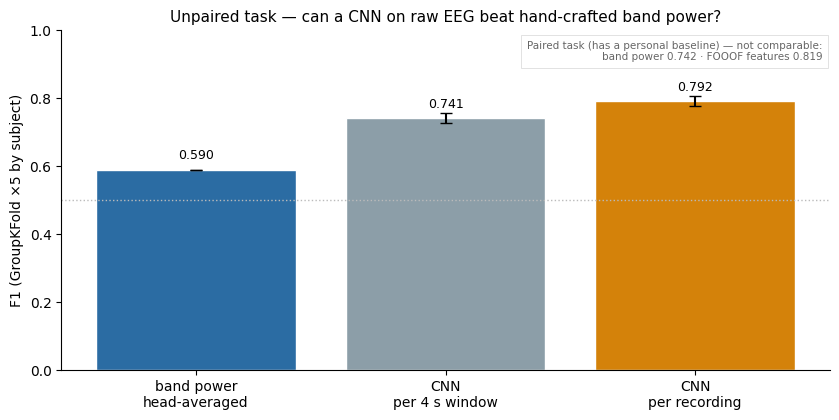


NB5a — 1D-CNN on raw EEG (eyes-closed, 20 channels, 4s windows)

  window-level     F1 = 0.741 ± 0.015
  recording-level  F1 = 0.792 ± 0.014
  NB4 Method 2     F1 = 0.590   (band power, same unpaired protocol)

This is the UNPAIRED task: the model sees one recording and must say whether it
came before or after the task battery, with no personal baseline. It is therefore
comparable to NB4 Method 2 only. The paired results (NB4 Method 3 = 0.742,
NB5c = 0.819) answer a different question — given both recordings of the same
person, which one is post — and are not a benchmark for this model.

Grouping is by SUBJECT, so the 24 windows cut from one recording — all carrying
the same label — can never be split across train and test. This matters more
here than in NB4, where each participant contributed two pre and two post
recordings, making subject identity uninformative about the label; here a single
recording supplies many identically labelled rows, so without grouping the model
could score

In [5]:
NB4_M2 = 0.590    # band power, GroupKFold, unpaired ← ตัวที่เทียบได้
NB4_M3 = 0.742    # paired — คนละโจทย์
NB5C   = 0.819    # paired + FOOOF — คนละโจทย์

cnn_w = folds['f1_window'].mean()
cnn_r = folds['f1_recording'].mean()

fig, ax = plt.subplots(figsize=(8.5, 4.3))
names = ['band power\nhead-averaged', 'CNN\nper 4 s window', 'CNN\nper recording']
vals  = [NB4_M2, cnn_w, cnn_r]
errs  = [0, folds['f1_window'].std(), folds['f1_recording'].std()]
cols  = ['#2b6ca3', '#8c9ea8', '#d4820a']

bars = ax.bar(names, vals, yerr=errs, capsize=4, color=cols, edgecolor='white')
ax.axhline(0.5, color='#bbb', ls=':', lw=1)
for b, v in zip(bars, vals):
    ax.text(b.get_x()+b.get_width()/2, v+0.03, f'{v:.3f}', ha='center', fontsize=9)

ax.set_ylim(0, 1); ax.set_ylabel('F1 (GroupKFold ×5 by subject)')
ax.set_title('Unpaired task — can a CNN on raw EEG beat hand-crafted band power?',
             fontsize=11)
ax.text(0.99, 0.97,
        f'Paired task (has a personal baseline) — not comparable:\n'
        f'band power {NB4_M3:.3f} · FOOOF features {NB5C:.3f}',
        transform=ax.transAxes, ha='right', va='top', fontsize=7.5, color='#666',
        bbox=dict(fc='white', ec='#ddd', lw=0.6))
ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.savefig('outputs/nb5a_comparison.png', dpi=150); plt.show()

print(f"""
NB5a — 1D-CNN on raw EEG (eyes-closed, {len(CHANS)} channels, {WIN_SEC}s windows)

  window-level     F1 = {cnn_w:.3f} ± {folds['f1_window'].std():.3f}
  recording-level  F1 = {cnn_r:.3f} ± {folds['f1_recording'].std():.3f}
  NB4 Method 2     F1 = {NB4_M2:.3f}   (band power, same unpaired protocol)

This is the UNPAIRED task: the model sees one recording and must say whether it
came before or after the task battery, with no personal baseline. It is therefore
comparable to NB4 Method 2 only. The paired results (NB4 Method 3 = {NB4_M3:.3f},
NB5c = {NB5C:.3f}) answer a different question — given both recordings of the same
person, which one is post — and are not a benchmark for this model.

Grouping is by SUBJECT, so the 24 windows cut from one recording — all carrying
the same label — can never be split across train and test. This matters more
here than in NB4, where each participant contributed two pre and two post
recordings, making subject identity uninformative about the label; here a single
recording supplies many identically labelled rows, so without grouping the model
could score highly by recognising the recording rather than the condition.
""")

In [6]:
# ── Cell 6 — two controls for the CNN result ──
from scipy.signal import butter, filtfilt
from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score

def run_cv(Xa, ya, ga, md_sub, tag, epochs=10, seed=42):
    # ตั้ง seed ทุกครั้งที่เรียก ไม่งั้นตัวเลขของ control แต่ละอันขยับทุกรอบที่รัน
    torch.manual_seed(seed); np.random.seed(seed)
    rows = []
    for k, (tr, te) in enumerate(GroupKFold(5).split(Xa, ya, groups=ga), 1):
        Xtr = torch.from_numpy(Xa[tr]); ytr = torch.from_numpy(ya[tr])
        Xte = torch.from_numpy(Xa[te]); yte = ya[te]
        model = RawEEGCNN().to(DEV)
        opt   = torch.optim.Adam(model.parameters(), lr=1e-3)
        lossf = nn.BCEWithLogitsLoss()
        dl    = DataLoader(TensorDataset(Xtr, ytr), batch_size=128,
                           shuffle=True, drop_last=True)
        model.train()
        for _ in range(epochs):
            for xb, yb in dl:
                xb, yb = xb.to(DEV), yb.to(DEV)
                opt.zero_grad(); lossf(model(xb), yb).backward(); opt.step()
        model.eval(); probs = []
        with torch.no_grad():
            for s in range(0, len(Xte), 512):
                probs.append(torch.sigmoid(model(Xte[s:s+512].to(DEV))).cpu().numpy())
        probs = np.concatenate(probs)
        sub = md_sub.iloc[te].copy(); sub['prob'] = probs; sub['y'] = yte
        rec = sub.groupby('recording').agg(prob=('prob','mean'), y=('y','first'))
        rows.append({'fold': k, 'f1_window': f1_score(yte, probs > 0.5),
                     'f1_recording': f1_score(rec['y'], rec['prob'] > 0.5),
                     'n_win': len(te), 'n_rec': len(rec)})
        print(f"  [{tag}] fold {k}: win {rows[-1]['f1_window']:.3f}  "
              f"rec {rows[-1]['f1_recording']:.3f}")
    f = pd.DataFrame(rows)
    print(f"[{tag}]  window {f.f1_window.mean():.3f}±{f.f1_window.std():.3f}   "
          f"recording {f.f1_recording.mean():.3f}±{f.f1_recording.std():.3f}\n")
    return f

X  = np.load(X_PATH); md = pd.read_csv(META_PATH)
y  = (md['condition'] == 'post').astype(np.float32).values
g  = md['subject'].values

# ══ CONTROL 1 — เฉพาะคนที่ pre/post ถูกลบ ICA component เท่ากัน ══
f4 = pd.read_csv('outputs/fooof_features_v4.csv')
f4 = (f4[f4.task == 'EyesClosed']
      .groupby(['subject','condition'])['n_muscle_excluded'].first().unstack())
ok_subj = f4.index[f4['pre'] == f4['post']]
m1 = md['subject'].isin(ok_subj).values
print(f"CONTROL 1 — matched ICA: {m1.sum()} windows, "
      f"{md.loc[m1,'subject'].nunique()} of {md['subject'].nunique()} subjects\n")
c1 = run_cv(X[m1], y[m1], g[m1], md[m1].reset_index(drop=True), 'matched-ICA')

# ══ CONTROL 2 — ตัดย่าน > 30 Hz ทิ้ง (ที่ EMG อยู่) ══
b, a = butter(4, 30 / (SF_NEW/2), btype='low')
Xlp = filtfilt(b, a, X, axis=2).astype(np.float32).copy()
print("CONTROL 2 — low-passed at 30 Hz (EMG band removed)\n")
c2 = run_cv(Xlp, y, g, md, 'lowpass-30Hz')

# ══ สรุป ══
base_w, base_r = folds.f1_window.mean(), folds.f1_recording.mean()
comp = pd.DataFrame([
    {'condition': 'full signal (baseline)', 'window': base_w,          'recording': base_r},
    {'condition': 'matched ICA count',      'window': c1.f1_window.mean(),
     'recording': c1.f1_recording.mean()},
    {'condition': 'low-pass 30 Hz',         'window': c2.f1_window.mean(),
     'recording': c2.f1_recording.mean()},
    {'condition': 'NB4 M2 — band power',    'window': np.nan, 'recording': 0.590},
])
print(comp.round(3).to_string(index=False))
comp.to_csv('outputs/nb5a_controls.csv', index=False)

CONTROL 1 — matched ICA: 7212 windows, 151 of 608 subjects

  [matched-ICA] fold 1: win 0.675  rec 0.703
  [matched-ICA] fold 2: win 0.680  rec 0.767
  [matched-ICA] fold 3: win 0.718  rec 0.788
  [matched-ICA] fold 4: win 0.693  rec 0.767
  [matched-ICA] fold 5: win 0.589  rec 0.553
[matched-ICA]  window 0.671±0.049   recording 0.715±0.096

CONTROL 2 — low-passed at 30 Hz (EMG band removed)

  [lowpass-30Hz] fold 1: win 0.739  rec 0.805
  [lowpass-30Hz] fold 2: win 0.733  rec 0.765
  [lowpass-30Hz] fold 3: win 0.749  rec 0.794
  [lowpass-30Hz] fold 4: win 0.761  rec 0.825
  [lowpass-30Hz] fold 5: win 0.730  rec 0.780
[lowpass-30Hz]  window 0.743±0.013   recording 0.794±0.023

             condition  window  recording
full signal (baseline)   0.741      0.792
     matched ICA count   0.671      0.715
        low-pass 30 Hz   0.743      0.794
   NB4 M2 — band power     NaN      0.590


In [7]:
# ── Cell 7 — size-matched control for Control 1 ──
rng      = np.random.default_rng(0)
subs     = md['subject'].unique()
n_target = md.loc[m1, 'subject'].nunique()          # 151
print(f"Drawing {n_target} random subjects, 3 repeats "
      f"(matched-ICA subset had the same count)\n")

reps = []
for r in range(3):
    pick = rng.choice(subs, size=n_target, replace=False)
    mk   = md['subject'].isin(pick).values
    f    = run_cv(X[mk], y[mk], g[mk], md[mk].reset_index(drop=True), f'random-{r+1}')
    reps.append({'rep': r+1, 'n_win': int(mk.sum()),
                 'window': f.f1_window.mean(), 'recording': f.f1_recording.mean()})

rnd = pd.DataFrame(reps)
print(rnd.round(3).to_string(index=False))
print(f"\nrandom subsets    : window {rnd.window.mean():.3f}   "
      f"recording {rnd.recording.mean():.3f}")
print(f"matched-ICA subset: window {c1.f1_window.mean():.3f}   "
      f"recording {c1.f1_recording.mean():.3f}")
print(f"full data         : window {folds.f1_window.mean():.3f}   "
      f"recording {folds.f1_recording.mean():.3f}")

rnd.to_csv('outputs/nb5a_size_control.csv', index=False)

Drawing 151 random subjects, 3 repeats (matched-ICA subset had the same count)

  [random-1] fold 1: win 0.587  rec 0.604
  [random-1] fold 2: win 0.652  rec 0.712
  [random-1] fold 3: win 0.705  rec 0.776
  [random-1] fold 4: win 0.763  rec 0.800
  [random-1] fold 5: win 0.701  rec 0.774
[random-1]  window 0.682±0.066   recording 0.733±0.079

  [random-2] fold 1: win 0.688  rec 0.750
  [random-2] fold 2: win 0.744  rec 0.800
  [random-2] fold 3: win 0.675  rec 0.738
  [random-2] fold 4: win 0.593  rec 0.653
  [random-2] fold 5: win 0.721  rec 0.806
[random-2]  window 0.684±0.058   recording 0.749±0.062

  [random-3] fold 1: win 0.769  rec 0.825
  [random-3] fold 2: win 0.716  rec 0.727
  [random-3] fold 3: win 0.694  rec 0.772
  [random-3] fold 4: win 0.717  rec 0.771
  [random-3] fold 5: win 0.725  rec 0.784
[random-3]  window 0.724±0.028   recording 0.776±0.035

 rep  n_win  window  recording
   1   7207   0.682      0.733
   2   7197   0.684      0.749
   3   7177   0.724      0.77

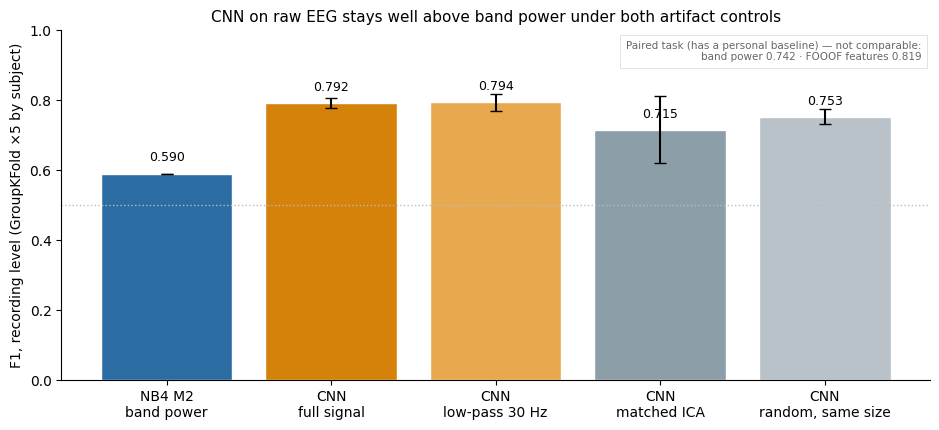

In [16]:
# ── Cell 8 — final figure with all controls ──
rows = [
    ('NB4 M2\nband power',      0.590, 0,                        '#2b6ca3'),
    ('CNN\nfull signal',        folds.f1_recording.mean(),  folds.f1_recording.std(),  '#d4820a'),
    ('CNN\nlow-pass 30 Hz',     c2.f1_recording.mean(),     c2.f1_recording.std(),     '#e8a94e'),
    ('CNN\nmatched ICA',        c1.f1_recording.mean(),     c1.f1_recording.std(),     '#8c9ea8'),
    ('CNN\nrandom, same size',  rnd.recording.mean(),       rnd.recording.std(),       '#b8c2c8'),
]
names, vals, errs, cols = zip(*rows)

fig, ax = plt.subplots(figsize=(9.5, 4.4))
bars = ax.bar(names, vals, yerr=errs, capsize=4, color=cols, edgecolor='white')
ax.axhline(0.5, color='#bbb', ls=':', lw=1)
for b, v in zip(bars, vals):
    ax.text(b.get_x()+b.get_width()/2, v+0.035, f'{v:.3f}', ha='center', fontsize=9)

ax.set_ylim(0, 1); ax.set_ylabel('F1, recording level (GroupKFold ×5 by subject)')
ax.set_title('CNN on raw EEG stays well above band power under both artifact controls',
             fontsize=11)
ax.text(0.99, 0.97,
        'Paired task (has a personal baseline) — not comparable:\n'
        'band power 0.742 · FOOOF features 0.819',
        transform=ax.transAxes, ha='right', va='top', fontsize=7.5, color='#666',
        bbox=dict(fc='white', ec='#ddd', lw=0.6))
ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.savefig('outputs/nb5a_controls.png', dpi=150); plt.show()

pd.DataFrame({'condition': names, 'f1_recording': vals, 'sd': errs}).to_csv(
    'outputs/nb5a_final.csv', index=False)

In [9]:
# ── Cell 9 — band-power baselines on the exact data the CNN sees ──
from scipy.signal import welch
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.metrics import f1_score

BANDS = [(1,4), (4,8), (8,10), (10,13), (13,20), (20,30), (30,45)]

# Welch แบบแบ่งก้อน กัน RAM
feats = []
for s in range(0, len(X), 4000):
    f, P = welch(X[s:s+4000], fs=SF_NEW, nperseg=SF_NEW*2, axis=2)
    feats.append(np.stack([np.log(P[:, :, (f>=lo)&(f<hi)].mean(axis=2))
                           for lo, hi in BANDS], axis=2).astype(np.float32))
F = np.concatenate(feats)                      # (N, 20 ch, 7 bands)
print(f"band-power features: {F.shape}")

F_perch = F.reshape(len(X), -1)                # 140 features — แยกทีละ channel
F_avg   = F.mean(axis=1)                       # 7 features — เฉลี่ยทั้งหัว (เหมือน NB4)

lr = Pipeline([('sc', StandardScaler()),
               ('clf', LogisticRegression(max_iter=2000, C=0.1))])

def rec_level(feat):
    """เฉลี่ย feature เป็นระดับการบันทึก แล้ว CV แบบ group by subject"""
    fd = pd.DataFrame(feat); fd['recording'] = md['recording'].values
    rx = fd.groupby('recording').mean()
    rm = md.groupby('recording').first().loc[rx.index]
    yr = (rm['condition'] == 'post').astype(int).values
    gr = rm['subject'].values
    s = cross_val_score(lr, rx.values, yr, groups=gr, cv=GroupKFold(5), scoring='f1')
    return s.mean(), s.std()

def win_then_aggregate(feat):
    """ฝึกระดับ window แล้วรวมคำทำนาย — เหมือนที่ CNN ทำทุกประการ"""
    out = []
    for tr, te in GroupKFold(5).split(feat, y, groups=g):
        p = lr.fit(feat[tr], y[tr]).predict_proba(feat[te])[:, 1]
        sub = md.iloc[te].copy(); sub['p'] = p; sub['yy'] = y[te]
        rec = sub.groupby('recording').agg(p=('p','mean'), yy=('yy','first'))
        out.append(f1_score(rec['yy'], rec['p'] > 0.5))
    return float(np.mean(out)), float(np.std(out))

a_m, a_s = rec_level(F_avg)
b_m, b_s = rec_level(F_perch)
c_m, c_s = win_then_aggregate(F_perch)

print(f"""
Decomposing the CNN's advantage (all recording-level F1, GroupKFold by subject)

  NB4 Method 2 — band power, EO+EC, head-averaged      0.590
  LR · 7 bands, head-averaged, EC only                 {a_m:.3f} ± {a_s:.3f}
  LR · 7 bands × 20 channels, EC only                  {b_m:.3f} ± {b_s:.3f}
  LR · same, trained per window like the CNN           {c_m:.3f} ± {c_s:.3f}
  CNN on raw signal                                    {folds.f1_recording.mean():.3f} ± {folds.f1_recording.std():.3f}

  gain from using EC only          {a_m-0.590:+.3f}
  gain from per-channel detail     {b_m-a_m:+.3f}
  gain beyond logistic regression  {folds.f1_recording.mean()-max(b_m,c_m):+.3f}   (ตัวเลขสุดท้ายดู Cell 13)
""")

pd.DataFrame({
    'model': ['NB4 M2', 'LR head-avg EC', 'LR per-channel EC',
              'LR per-window', 'CNN raw'],
    'f1_recording': [0.590, a_m, b_m, c_m, folds.f1_recording.mean()],
    'sd': [np.nan, a_s, b_s, c_s, folds.f1_recording.std()],
}).to_csv('outputs/nb5a_fair_baseline.csv', index=False)

band-power features: (28942, 20, 7)

Decomposing the CNN's advantage (all recording-level F1, GroupKFold by subject)

  NB4 Method 2 — band power, EO+EC, head-averaged      0.590
  LR · 7 bands, head-averaged, EC only                 0.628 ± 0.020
  LR · 7 bands × 20 channels, EC only                  0.710 ± 0.024
  LR · same, trained per window like the CNN           0.714 ± 0.017
  CNN on raw signal                                    0.792 ± 0.014

  gain from using EC only          +0.038
  gain from per-channel detail     +0.082
  gain beyond logistic regression  +0.077   (ตัวเลขสุดท้ายดู Cell 13)



In [10]:
# ── Cell 10 — flip labels for half the subjects; should collapse to ~0.5 ──
rng_s  = np.random.default_rng(1)
subs   = md['subject'].unique()
flip   = set(rng_s.choice(subs, size=len(subs)//2, replace=False))
y_shuf = np.where(md['subject'].isin(flip).values, 1 - y, y).astype(np.float32)

print(f"Flipped {len(flip)} of {len(subs)} subjects (whole subject, both recordings)\n")
c0 = run_cv(X, y_shuf, g, md, 'shuffled-labels')

print(f"""
real labels     : recording F1 = {folds.f1_recording.mean():.3f}
shuffled labels : recording F1 = {c0.f1_recording.mean():.3f}

A score near chance under shuffling confirms that no information leaks through
the fold structure, the window extraction, or the per-recording aggregation.
""")
c0.to_csv('outputs/nb5a_shuffled.csv', index=False)

Flipped 304 of 608 subjects (whole subject, both recordings)

  [shuffled-labels] fold 1: win 0.506  rec 0.496
  [shuffled-labels] fold 2: win 0.473  rec 0.435
  [shuffled-labels] fold 3: win 0.512  rec 0.502
  [shuffled-labels] fold 4: win 0.457  rec 0.400
  [shuffled-labels] fold 5: win 0.556  rec 0.574
[shuffled-labels]  window 0.501±0.038   recording 0.481±0.067


real labels     : recording F1 = 0.792
shuffled labels : recording F1 = 0.481

A score near chance under shuffling confirms that no information leaks through
the fold structure, the window extraction, or the per-recording aggregation.



In [11]:
# ── Cell 11 — is the CNN's edge just spectral resolution? ──
from scipy.signal import welch
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score

REGIONS = {'frontal':   slice(0, 7),      # CHANS เรียงตามบริเวณอยู่แล้ว
           'central':   slice(7, 14),
           'occipital': slice(14, 20)}

# ── สเปกตรัมเต็มความละเอียด 1–45 Hz (bin ละ 0.5 Hz) ──
spec = []
for s in range(0, len(X), 4000):
    f, P = welch(X[s:s+4000], fs=SF_NEW, nperseg=SF_NEW*2, axis=2)
    m = (f >= 1) & (f <= 45)
    spec.append(np.log(P[:, :, m]).astype(np.float32))
S = np.concatenate(spec)                       # (N, 20 ch, n_freq)
freqs_kept = f[m]
print(f"full spectrum: {S.shape}  ({len(freqs_kept)} bins, {freqs_kept[1]-freqs_kept[0]:.2f} Hz apart)")

S_reg = np.stack([S[:, sl, :].mean(axis=1) for sl in REGIONS.values()], axis=1)
S_reg = S_reg.reshape(len(S), -1)              # 3 regions × n_freq
S_all = S.reshape(len(S), -1)                  # 20 channels × n_freq
print(f"per-region: {S_reg.shape[1]} features   per-channel: {S_all.shape[1]} features")

lr_s = Pipeline([('sc', StandardScaler()),
                 ('clf', LogisticRegression(max_iter=3000, C=0.01))])

def rec_cv(feat):
    fd = pd.DataFrame(feat); fd['recording'] = md['recording'].values
    rx = fd.groupby('recording').mean()
    rm = md.groupby('recording').first().loc[rx.index]
    yr = (rm['condition'] == 'post').astype(int).values
    gr = rm['subject'].values
    out = []
    for tr, te in GroupKFold(5).split(rx.values, yr, groups=gr):
        p = lr_s.fit(rx.values[tr], yr[tr]).predict(rx.values[te])
        out.append(f1_score(yr[te], p))
    return float(np.mean(out)), float(np.std(out))

r_m, r_s = rec_cv(S_reg)
a_m, a_s = rec_cv(S_all)

prev = pd.read_csv('outputs/nb5a_fair_baseline.csv').set_index('model')['f1_recording']
print(f"""
What does the network add beyond the spectrum?

  LR ·  7 bands × 20 channels              {prev['LR per-channel EC']:.3f}
  LR · full spectrum × 3 regions           {r_m:.3f} ± {r_s:.3f}
  LR · full spectrum × 20 channels         {a_m:.3f} ± {a_s:.3f}
  CNN on the raw waveform                  {prev['CNN raw']:.3f}

  gain from spectral resolution alone      {max(r_m, a_m) - prev['LR per-channel EC']:+.3f}
  remaining gain from the network          {prev['CNN raw'] - max(r_m, a_m):+.3f}
""")

pd.DataFrame({'model': ['LR 7 bands', 'LR full spectrum, 3 regions',
                        'LR full spectrum, 20 channels', 'CNN raw'],
              'f1_recording': [prev['LR per-channel EC'], r_m, a_m, prev['CNN raw']],
              'sd': [np.nan, r_s, a_s, np.nan]}).to_csv(
    'outputs/nb5a_spectral_resolution.csv', index=False)

full spectrum: (28942, 20, 89)  (89 bins, 0.50 Hz apart)
per-region: 267 features   per-channel: 1780 features

What does the network add beyond the spectrum?

  LR ·  7 bands × 20 channels              0.710
  LR · full spectrum × 3 regions           0.681 ± 0.033
  LR · full spectrum × 20 channels         0.706 ± 0.024
  CNN on the raw waveform                  0.792

  gain from spectral resolution alone      -0.004
  remaining gain from the network          +0.086



In [12]:
# ── Cell 12 — nonlinearity or temporal structure? ──
from scipy.signal import welch
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score

BANDS = [(1,4), (4,8), (8,10), (10,13), (13,20), (20,30), (30,45)]

feats = []
for s in range(0, len(X), 4000):
    f, P = welch(X[s:s+4000], fs=SF_NEW, nperseg=SF_NEW*2, axis=2)
    feats.append(np.stack([np.log(P[:, :, (f>=lo)&(f<hi)].mean(axis=2))
                           for lo, hi in BANDS], axis=2).astype(np.float32))
F = np.concatenate(feats).reshape(len(X), -1)      # 140 features
print(f"band features: {F.shape}")

# ยุบเป็นระดับการบันทึก (เหมือนทุกการเทียบก่อนหน้า)
fd = pd.DataFrame(F); fd['recording'] = md['recording'].values
RX = fd.groupby('recording').mean()
RM = md.groupby('recording').first().loc[RX.index]
YR = (RM['condition'] == 'post').astype(int).values
GR = RM['subject'].values
print(f"recording level: {RX.shape}")

MODELS = {
    'LogReg (linear)':   Pipeline([('sc', StandardScaler()),
                                   ('clf', LogisticRegression(max_iter=3000, C=0.1))]),
    'RandomForest':      RandomForestClassifier(n_estimators=500, min_samples_leaf=3,
                                                random_state=42, n_jobs=-1),
    'HistGradBoosting':  HistGradientBoostingClassifier(max_iter=300, random_state=42),
    'MLP (2 hidden)':    Pipeline([('sc', StandardScaler()),
                                   ('clf', MLPClassifier(hidden_layer_sizes=(128, 64),
                                                         max_iter=800, random_state=42))]),
}

print("\nNonlinear models on the SAME spectral features (7 bands × 20 channels)\n")
rows = []
for name, mdl in MODELS.items():
    sc = []
    for tr, te in GroupKFold(5).split(RX.values, YR, groups=GR):
        from sklearn.base import clone
        m = clone(mdl).fit(RX.values[tr], YR[tr])
        sc.append(f1_score(YR[te], m.predict(RX.values[te])))
    rows.append({'model': name, 'f1': float(np.mean(sc)), 'sd': float(np.std(sc))})
    print(f"  {name:<20} F1 = {np.mean(sc):.3f} ± {np.std(sc):.3f}")

res = pd.DataFrame(rows)
best_nl = res[res.model != 'LogReg (linear)']['f1'].max()
cnn = folds.f1_recording.mean()       # ไม่ hardcode เพื่อไม่ให้ค้างถ้ารัน CNN ใหม่

print(f"""
  CNN on the raw waveform          {cnn:.3f}

  best nonlinear model on spectra  {best_nl:.3f}
  gain from nonlinearity alone     {best_nl - res.query("model=='LogReg (linear)'")['f1'].iloc[0]:+.3f}
  remaining gain for the waveform  {cnn - best_nl:+.3f}
""")
print("หมายเหตุ  เซลล์นี้ยุบเป็นระดับการบันทึกก่อนฝึก ซึ่งไม่เหมือนที่ CNN ทำ\n"
      "          ตัวเลขที่ใช้สรุปคือ Cell 13 ที่ฝึกระดับหน้าต่างเหมือนกันทุกจุด")
res.to_csv('outputs/nb5a_nonlinearity.csv', index=False)

band features: (28942, 140)
recording level: (1211, 140)

Nonlinear models on the SAME spectral features (7 bands × 20 channels)

  LogReg (linear)      F1 = 0.710 ± 0.024
  RandomForest         F1 = 0.678 ± 0.021
  HistGradBoosting     F1 = 0.686 ± 0.018
  MLP (2 hidden)       F1 = 0.686 ± 0.026

  CNN on the raw waveform          0.792

  best nonlinear model on spectra  0.686
  gain from nonlinearity alone     -0.024
  remaining gain for the waveform  +0.106

หมายเหตุ  เซลล์นี้ยุบเป็นระดับการบันทึกก่อนฝึก ซึ่งไม่เหมือนที่ CNN ทำ
          ตัวเลขที่ใช้สรุปคือ Cell 13 ที่ฝึกระดับหน้าต่างเหมือนกันทุกจุด


In [13]:
# ── Cell 13 — nonlinear models trained at WINDOW level, like the CNN ──
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.base import clone
from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score
import time

# F = (28942, 140) จาก Cell 12 — ถ้ายังอยู่ในหน่วยความจำก็ใช้ต่อได้เลย
print(f"window-level features: {F.shape}")

MODELS_W = {
    'LogReg':           Pipeline([('sc', StandardScaler()),
                                  ('clf', LogisticRegression(max_iter=3000, C=0.1))]),
    'RandomForest':     RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                               random_state=42, n_jobs=-1),
    'HistGradBoosting': HistGradientBoostingClassifier(max_iter=400, random_state=42),
}

rows = []
for name, mdl in MODELS_W.items():
    t0, sc = time.time(), []
    for tr, te in GroupKFold(5).split(F, y, groups=g):
        m = clone(mdl).fit(F[tr], y[tr])
        p = m.predict_proba(F[te])[:, 1]
        sub = md.iloc[te].copy(); sub['p'] = p; sub['yy'] = y[te]
        rec = sub.groupby('recording').agg(p=('p', 'mean'), yy=('yy', 'first'))
        sc.append(f1_score(rec['yy'], rec['p'] > 0.5))
    rows.append({'model': name, 'f1': float(np.mean(sc)), 'sd': float(np.std(sc))})
    print(f"  {name:<18} F1 = {np.mean(sc):.3f} ± {np.std(sc):.3f}   ({time.time()-t0:.0f}s)")

resw = pd.DataFrame(rows)
best_w = resw['f1'].max()
cnn    = folds.f1_recording.mean()

print(f"""
Trained on the same 28,942 windows, aggregated the same way:

  best spectral model (any kind)   {best_w:.3f}
  CNN on the raw waveform          {cnn:.3f}
  gain that only the waveform gives {cnn - best_w:+.3f}
""")
resw.to_csv('outputs/nb5a_nonlinear_window.csv', index=False)

window-level features: (28942, 140)
  LogReg             F1 = 0.714 ± 0.017   (1s)
  RandomForest       F1 = 0.696 ± 0.027   (61s)
  HistGradBoosting   F1 = 0.718 ± 0.022   (37s)

Trained on the same 28,942 windows, aggregated the same way:

  best spectral model (any kind)   0.718
  CNN on the raw waveform          0.792
  gain that only the waveform gives +0.073



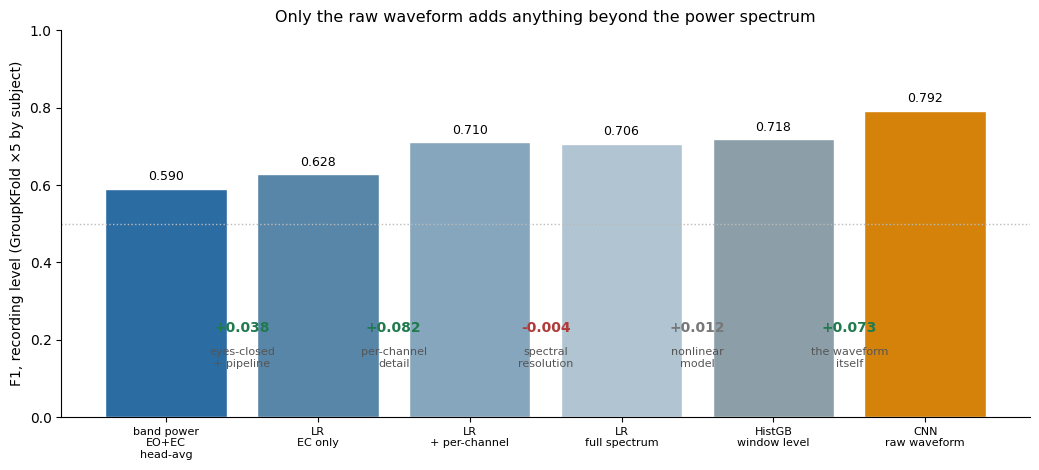

In [14]:
# ── Cell 14 — where the advantage comes from, complete ladder ──
fair = pd.read_csv('outputs/nb5a_fair_baseline.csv').set_index('model')['f1_recording']
spec = pd.read_csv('outputs/nb5a_spectral_resolution.csv').set_index('model')['f1_recording']
nlw  = pd.read_csv('outputs/nb5a_nonlinear_window.csv').set_index('model')['f1']

steps = [
    ('band power\nEO+EC\nhead-avg',    0.590,                              '#2b6ca3'),
    ('LR\nEC only',                    fair['LR head-avg EC'],             '#5886a8'),
    ('LR\n+ per-channel',              fair['LR per-channel EC'],          '#86a6bd'),
    ('LR\nfull spectrum',              spec['LR full spectrum, 20 channels'], '#b0c4d1'),
    ('HistGB\nwindow level',           nlw['HistGradBoosting'],            '#8c9ea8'),
    ('CNN\nraw waveform',              folds.f1_recording.mean(),          '#d4820a'),
]
nm, vl, cl = zip(*steps)

fig, ax = plt.subplots(figsize=(10.5, 4.8))
bars = ax.bar(nm, vl, color=cl, edgecolor='white')
ax.axhline(0.5, color='#bbb', ls=':', lw=1)
for b, v in zip(bars, vl):
    ax.text(b.get_x()+b.get_width()/2, v+0.022, f'{v:.3f}', ha='center', fontsize=9)

ann = [(0.5, vl[1]-vl[0], 'eyes-closed\n+ pipeline'),
       (1.5, vl[2]-vl[1], 'per-channel\ndetail'),
       (2.5, vl[3]-vl[2], 'spectral\nresolution'),
       (3.5, vl[4]-vl[3], 'nonlinear\nmodel'),
       (4.5, vl[5]-vl[4], 'the waveform\nitself')]
for xi, dv, lab in ann:
    col = '#1F7A4D' if dv > 0.02 else ('#b03a3a' if dv < -0.002 else '#777')
    ax.text(xi, 0.22, f'{dv:+.3f}', ha='center', fontsize=10, color=col, fontweight='bold')
    ax.text(xi, 0.13, lab, ha='center', fontsize=8, color='#555')

ax.set_ylim(0, 1)
ax.set_ylabel('F1, recording level (GroupKFold ×5 by subject)')
ax.set_title('Only the raw waveform adds anything beyond the power spectrum',
             fontsize=11.5)
ax.tick_params(axis='x', labelsize=8)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.savefig('outputs/nb5a_decomposition.png', dpi=150,
                                bbox_inches='tight')
plt.show()

In [17]:
fair = pd.read_csv('outputs/nb5a_fair_baseline.csv').set_index('model')['f1_recording']
nlw  = pd.read_csv('outputs/nb5a_nonlinear_window.csv').set_index('model')['f1']
best_spec = nlw.max()          # โมเดลสเปกตรัมที่ดีที่สุด ฝึกระดับหน้าต่างเหมือน CNN

# ตัวเลข control คำนวณสด จาก c1 (ICA เท่ากัน) · c2 (low-pass) · rnd (กลุ่มสุ่ม)
m_ica, m_sd = c1.f1_recording.mean(), c1.f1_recording.std()
r_lo, r_hi  = rnd.recording.min(), rnd.recording.max()

print(f"""
5. A CNN ON THE RAW SIGNAL ADDS REAL INFORMATION, BUT LESS THAN THE HEADLINE
   NUMBER SUGGESTS.
   On the unpaired task — one recording in, before-or-after out — a small
   1D convolutional network (40k parameters, 4-second windows, 20 channels,
   grouped by subject, hyperparameters fixed in advance and never tuned on a
   test fold) reaches F1 = {fair['CNN raw']:.3f} at the recording level, against
   {0.590:.3f} for the band-power model of NB4. That gap of {fair['CNN raw']-0.590:+.3f} is
   not all attributable to the network. Decomposed on identical data it is
   {fair['LR head-avg EC']-0.590:+.3f} for analysing eyes-closed alone,
   {fair['LR per-channel EC']-fair['LR head-avg EC']:+.3f} for keeping channels separate rather than averaging
   across the head, and {fair['CNN raw']-best_spec:+.3f} for the architecture itself over the best
   spectral model of any kind — linear, forest or boosted — given the same
   windows, the same channels and the same aggregation. Spatial and spectral
   detail matters about as much as the model.

   Four controls support the result. Removing everything above 30 Hz, where
   muscle activity dominates, leaves the score essentially unchanged
   ({c2.f1_recording.mean():.3f}). Restricting to recordings whose halves had the same number
   of ICA components removed gives {m_ica:.3f}, slightly below random subsets of the
   same size ({r_lo:.3f}–{r_hi:.3f}). That gap is within the fold-to-fold variability of
   the matched subset itself (sd {m_sd:.3f}), but a partial contribution from
   artifact load cannot be ruled out; the score remains well above the
   band-power baseline ({0.590:.3f}). Flipping the labels of half the subjects
   collapses performance to chance, confirming that nothing leaks through the
   fold structure or the aggregation. What the network uses therefore lies
   below 30 Hz, where alpha and the aperiodic slope live — consistent with the
   group-level results, read at a finer resolution than band averages allow.

   This is the unpaired question and is not comparable to the paired results
   (paired band power = 0.742, paired FOOOF features = 0.819). Note also that
   every window is z-scored per channel, so the network cannot read absolute
   amplitude — offset and gain changes are removed, though changes in spectral
   shape remain visible. The notable part is how close it comes: without ever
   seeing the person's own baseline, the network approaches what hand-crafted
   features achieve with one.
""")


5. A CNN ON THE RAW SIGNAL ADDS REAL INFORMATION, BUT LESS THAN THE HEADLINE
   NUMBER SUGGESTS.
   On the unpaired task — one recording in, before-or-after out — a small
   1D convolutional network (40k parameters, 4-second windows, 20 channels,
   grouped by subject, hyperparameters fixed in advance and never tuned on a
   test fold) reaches F1 = 0.792 at the recording level, against
   0.590 for the band-power model of NB4. That gap of +0.202 is
   not all attributable to the network. Decomposed on identical data it is
   +0.038 for analysing eyes-closed alone,
   +0.082 for keeping channels separate rather than averaging
   across the head, and +0.073 for the architecture itself over the best
   spectral model of any kind — linear, forest or boosted — given the same
   windows, the same channels and the same aggregation. Spatial and spectral
   detail matters about as much as the model.

   Four controls support the result. Removing everything above 30 Hz, where
   muscle activity